# Manuel ve rastgele arama ile 3×3 nested CV

Her dış katta iki eşit arama bütçesi, üç iç kat ve 12 aday kullanılır. Adaylar ortalama AP ile sıralanır. Yeniden eğitim talimatları README'dedir.

In [1]:
from pathlib import Path
import subprocess
import sys

ROOT = Path.cwd()
if not (ROOT / "src/experiment.py").exists():
    ROOT = ROOT / "YapayS-Vize"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "https://github.com/JustLotus/YapayS-Vize.git",
                        str(ROOT)], check=True)
import pandas as pd
from IPython.display import Image, display

def table(name, maximum=None):
    frame = pd.read_csv(ROOT / "results" / name)
    if maximum is not None:
        frame = frame.head(maximum)
    display(frame.round(4))

def figure(name, width=680):
    display(Image(filename=str(ROOT / "figures" / name), width=width))


In [2]:
# Yeniden üretmek için temiz bir depo kopyasında True yapın.
RUN_EXPERIMENT = False
if RUN_EXPERIMENT:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r",
                    str(ROOT / "requirements.txt")], check=True)
    for stage in ('outer', 'lock'):
        subprocess.run([sys.executable, "src/experiment.py", stage], cwd=ROOT, check=True)


,fold,method,candidate,seconds,AP,ROC_AUC,Accuracy,Precision,Sensitivity,Specificity,F1,Balanced_Accuracy
0,1,Manual,M3,1.5505,0.4461,0.7827,0.8999,0.6486,0.1983,0.9867,0.3038,0.5925
1,1,Random,R6,0.6772,0.4050,0.7772,0.9008,0.6875,0.1818,0.9898,0.2876,0.5858
2,1,Dummy,Dummy,0.0466,0.1101,0.5000,0.8899,0.0000,0.0000,1.0000,0.0000,0.5000
3,1,LogisticRegression,LogisticRegression,0.0809,0.4372,0.7815,0.8999,0.6170,0.2397,0.9816,0.3452,0.6106
4,2,Manual,M5,0.7222,0.4666,0.7809,0.9071,0.7500,0.2250,0.9908,0.3462,0.6079
5,2,Random,R6,1.2390,0.4696,0.7780,0.9080,0.7209,0.2583,0.9877,0.3804,0.6230
6,2,Dummy,Dummy,0.0440,0.1093,0.5000,0.8907,0.0000,0.0000,1.0000,0.0000,0.5000
7,2,LogisticRegression,LogisticRegression,0.0676,0.4577,0.7731,0.9062,0.6735,0.2750,0.9836,0.3905,0.6293
8,3,Manual,M1,1.1484,0.3573,0.7273,0.8962,0.5882,0.1667,0.9857,0.2597,0.5762
9,3,Random,R4,1.1572,0.3234,0.7305,0.8925,0.5250,0.1750,0.9806,0.2625,0.5778


,method,AP_mean,AP_std,ROC_AUC_mean,ROC_AUC_std,Accuracy_mean,Accuracy_std,Precision_mean,Precision_std,Sensitivity_mean,Sensitivity_std,Specificity_mean,Specificity_std,F1_mean,F1_std,Balanced_Accuracy_mean,Balanced_Accuracy_std,seconds_mean,seconds_std
0,Dummy,0.1096,0.0005,0.5000,0.0000,0.8904,0.0005,0.0000,0.0000,0.0000,0.0000,1.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0444,0.0020
1,LogisticRegression,0.4147,0.0577,0.7592,0.0316,0.9014,0.0043,0.6360,0.0324,0.2299,0.0507,0.9840,0.0026,0.3362,0.0594,0.6069,0.0244,0.0787,0.0102
2,Manual,0.4233,0.0581,0.7637,0.0315,0.9011,0.0056,0.6623,0.0817,0.1967,0.0292,0.9877,0.0027,0.3032,0.0432,0.5922,0.0159,1.1404,0.4142
3,Random,0.3993,0.0733,0.7619,0.0272,0.9005,0.0077,0.6445,0.1048,0.2051,0.0463,0.9860,0.0048,0.3101,0.0621,0.5955,0.0241,1.0245,0.3035


,group,candidate,mean_AP,sd_AP,seconds,mean_best_epoch
0,Manual,M1,0.4323,0.0178,3.6911,15.3333
1,Manual,M6,0.4323,0.0178,1.9823,15.3333
2,Manual,M3,0.4322,0.0170,5.2491,105.3333
3,Manual,M2,0.4314,0.0170,2.3937,24.6667
4,Random,R1,0.4313,0.0143,2.2975,25.6667
5,Random,R2,0.4300,0.0132,11.3559,66.6667
6,Random,R5,0.4201,0.0266,5.0314,13.3333
7,Random,R6,0.4170,0.0171,2.4498,20.0000
8,Manual,M4,0.4168,0.0333,2.5989,28.0000
9,Manual,M5,0.4148,0.0094,2.1682,12.0000


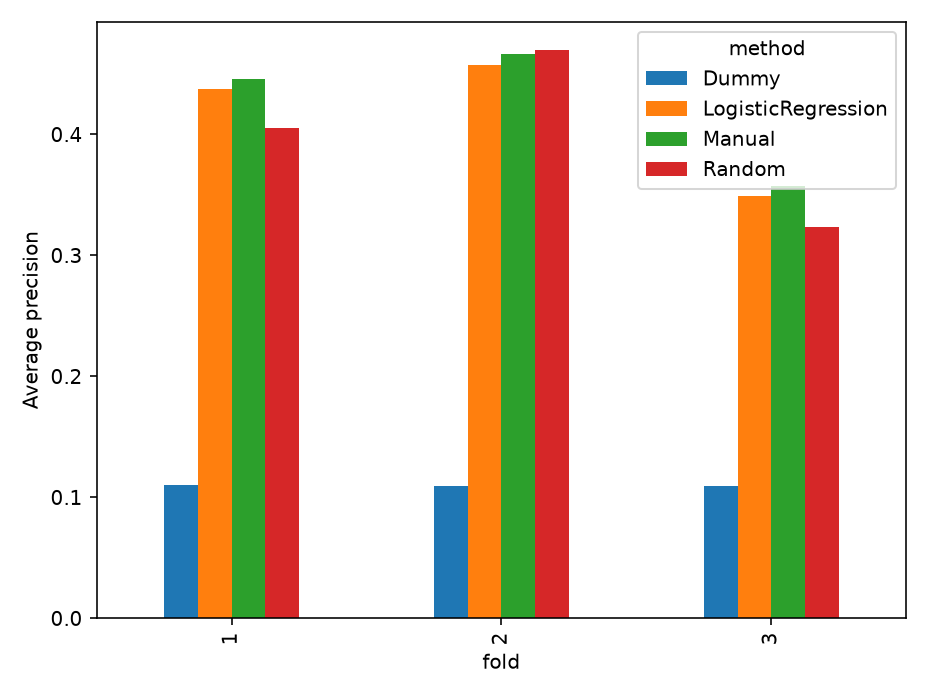

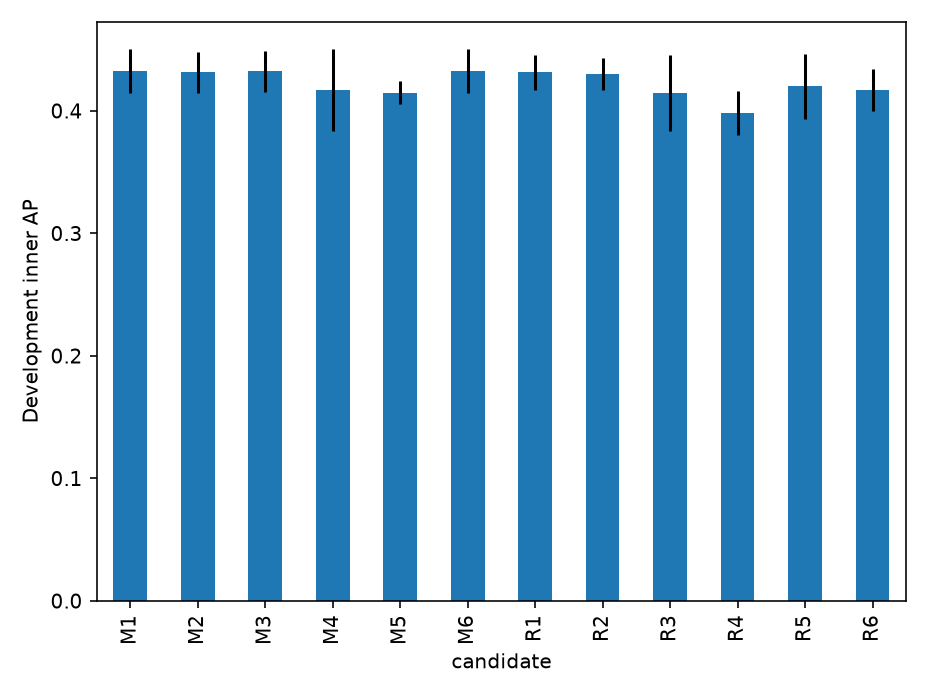

In [3]:
table("outer_cv_results.csv")
table("outer_cv_summary.csv")
table("final_inner_search.csv")
figure("outer_ap_comparison.png")
figure("final_candidate_comparison.png")


In [4]:
import json
print(json.loads((ROOT / "results/final_hyperparameters.json").read_text(encoding="utf-8")))
table("test_predictions_locked.csv", 5)


{'config': {'optimizer': 'AdamW', 'hidden': [32], 'scaler': 'Standard', 'lr': 0.001, 'wd': 0.0001, 'scheduler': True, 'batch': 64, 'dropout': 0.0, 'activation': 'ReLU', 'clip': False, 'id': 'M1'}, 'primary_seed': 31163, 'threshold': 0.5, 'selection': 'highest mean inner AP; ties by candidate identifier', 'models': [{'best_epoch': 6, 'stopped_epoch': 21, 'seconds': 0.6017975999857299, 'parameters': 2081, 'input_width': 63, 'split_seed': 31563, 'weight_seed': 31163, 'status': 'early_stop'}, {'best_epoch': 3, 'stopped_epoch': 18, 'seconds': 0.5720379999838769, 'parameters': 2081, 'input_width': 63, 'split_seed': 31563, 'weight_seed': 31164, 'status': 'early_stop'}, {'best_epoch': 9, 'stopped_epoch': 24, 'seconds': 0.6135679999715649, 'parameters': 2081, 'input_width': 63, 'split_seed': 31563, 'weight_seed': 31165, 'status': 'early_stop'}], 'reference_seconds': {'Dummy': 0.030816800019238144, 'LogisticRegression': 0.058218799997121096}}


,row_index,prob_31163,pred_31163,prob_31164,pred_31164,prob_31165,pred_31165,prob_Dummy,pred_Dummy,prob_LogisticRegression,pred_LogisticRegression
0,2728,0.0611,0,0.0692,0,0.0573,0,0.1096,0,0.0558,0
1,1786,0.0907,0,0.1186,0,0.0826,0,0.1096,0,0.0853,0
2,617,0.0438,0,0.0505,0,0.0398,0,0.1096,0,0.0423,0
3,2912,0.6975,1,0.5896,1,0.7554,1,0.1096,0,0.5800,1
4,426,0.0414,0,0.0513,0,0.0472,0,0.1096,0,0.0430,0
